# Final project
## Imports

In [270]:
import numpy as np
import pandas as pd
import xarray as xr
import math
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_squared_error, r2_score

## Data
### Load data

In [271]:
LAT_LON = ["Lat", "Lon"]

# LPJ-GUESS 
lpj_df = pd.read_csv("data/LPJ-GUESS_output_BERN1.csv")
lpj_df = lpj_df.rename(columns={col: col + f"_lpj" for col in lpj_df.columns if not col in LAT_LON})

# Grid information
grid_df = pd.read_csv("data/gridlist_pan_gfed_ISO3_UN_ecoregion.txt", sep=' ')
grid_df = grid_df.rename(columns={col: col + f"_grid" for col in grid_df.columns if not col in LAT_LON})

# Soil texture
soil_df = pd.read_csv("data/soilmap.dat", sep="\t")
soil_df = soil_df.dropna().rename(columns={"lon": "Lon", "lat": "Lat"})
soil_df = soil_df.rename(columns={col: col + f"_soil" for col in soil_df.columns if not col in LAT_LON})

# Load all climate statistics datafiles and put in one dictionary
stats_files = {
    "tswrf": "Tswrfdaymean1961_1990_stats.csv",
    "pre": "Predaymean1961_1990_stats.csv",
    "tmp": "Tmpdaymean1961_1990_stats.csv",
    "tmax": "Tmaxdaymean1961_1990_stats.csv",
    "tmin": "Tmindaymean1961_1990_stats.csv"}

stats_df = {}
for name, path in stats_files.items():
    df = pd.read_csv("data/" + path)
    df = df.rename(columns={col: col + f"_{name}" for col in df.columns if not col in LAT_LON})
    stats_df[name] = df

# Load all climate datafiles and put in one dictionary
climate_files = {
    "tswrf": "Tswrfdaymean1961_1990.csv",
    "pre": "Predaymean1961_1990.csv",
    "tmp": "Tmpdaymean1961_1990.csv",
    "tmax": "Tmaxdaymean1961_1990.csv",
    "tmin": "Tmindaymean1961_1990.csv"
}

climate_df = {}
for name, path in climate_files.items():
    df = pd.read_csv("data/" + path)
    climate_df[name] = df

# NCSCD Non-soil coverage data
nonsoil_ds = xr.open_dataset("./data/NCSCDv2_Circumpolar_netCDF_05deg/NCSCDv2_Circumpolar_WGS84_nonsoil_pct_05deg.nc")

# NCSCD Soil organic carbon data
soc_ds = xr.open_dataset("./data/NCSCDv2_Circumpolar_netCDF_05deg/NCSCDv2_Circumpolar_WGS84_SOCC100_05deg.nc")

### Data wrangling
#### Create climate concatenated info

In [272]:
# Identify daily columns
day_cols = [f"Day{i}" for i in range(1, 366)]

# Calculate annual mean temperature
tmp = climate_df["tmp"]
temperature_df = tmp[LAT_LON].copy()
temperature_df["AnnualMeanTmp_con"] = tmp[day_cols].mean(axis=1)

# Calculate annual extreme temperature range
tmax = climate_df["tmax"]
tmin = climate_df["tmin"]
temperature_df["ExtremeRangeTmp_con"] = tmax[day_cols].max(axis=1) - tmin[day_cols].min(axis=1)

# Calculate annual mean total solar radiation
tswrf = climate_df["tswrf"]

radiation_df = tswrf[LAT_LON].copy()
radiation_df["AnnualMeanTswrf_con"] = tswrf[day_cols].mean(axis=1)
radiation_df["AnnualTotalTswrf_con"] = tswrf[day_cols].sum(axis=1)

# Calculate annual precipitation features
pre = climate_df["pre"]

precipitation_df = pre[LAT_LON].copy()
precipitation_df["AnnualMeanPre_con"] = pre[day_cols].mean(axis=1)
precipitation_df["AnnualTotalPre_con"] = pre[day_cols].sum(axis=1)
precipitation_df["ExtremePre_con"] = pre[day_cols].max(axis=1)

#### Merge dataframes

In [273]:
# Combine lpj_df with soil organic carbon (SOC) values from NCSCD
lpj_df = lpj_df[lpj_df["Lat"].between(soc_ds["lat"].min().item(), soc_ds["lat"].max().item())].copy() # Keep LPJ cells within the NCSCD latitude range
lpj_coords = xr.Dataset({"lon": ("obs", lpj_df["Lon"].values), "lat": ("obs", lpj_df["Lat"].values)}) # Match the remaining LPJ coordinates to the nearest NCSCD grid cells
matched_soc = soc_ds["NCSCDv2"].sel(lon=lpj_coords.lon, lat=lpj_coords.lat, method="nearest") # Find the nearest NCSCD cell for every LPJ cell
lpj_df["NCSCD_SOCC100"] = matched_soc.values # Add the SOC values to the dataframe

# Combine lpj_df with non-soil coverage values from NCSCDv2
lpj_df = lpj_df[lpj_df["Lat"].between(nonsoil_ds["lat"].min().item(), nonsoil_ds["lat"].max().item())].copy()  # Keep LPJ cells within the non-soil latitude range
lpj_coords = xr.Dataset({"lon": ("obs", lpj_df["Lon"].values), "lat": ("obs", lpj_df["Lat"].values)})  # Match LPJ coordinates to NCSCD grid cells
matched_nonsoil = nonsoil_ds["NCSCDv2"].sel(lon=lpj_coords.lon, lat=lpj_coords.lat, method="nearest")  # Find the nearest non-soil coverage cell for every LPJ cell
lpj_df["NCSCD_nonsoil_pct"] = matched_nonsoil.values  # Add non-soil coverage (%) to the dataframe

# Add soil and grid info
merged_df = lpj_df.merge(grid_df, on=LAT_LON, how="inner").merge(soil_df, on=LAT_LON, how="inner") 

# Add climate statistics
for name, df in stats_df.items(): 
    merged_df = merged_df.merge(df, on=LAT_LON, how="inner")

# Add my own temperature statistics
merged_df = merged_df.merge(temperature_df, on=LAT_LON, how="inner" )
merged_df = merged_df.merge(radiation_df, on=["Lon", "Lat"], how="left")
merged_df = merged_df.merge(precipitation_df, on=["Lon", "Lat"], how="left")

#merged_df.head()
print(merged_df.columns.tolist())

['Lon', 'Lat', 'NPP_lpj', 'SoilR_lpj', 'MaxBiomeCmax_lpj', 'MaxBiomeLAI_lpj', 'VegC_lpj', 'LitterC_lpj', 'SoilC_lpj', 'Biome_Cmax_lpj', 'Biome_LAI_lpj', 'Biome_obs_lpj', 'NCSCD_SOCC100', 'NCSCD_nonsoil_pct', 'GFED-region_grid', 'Pan_2007_grid', 'ISO3_grid', 'UN_grid', 'Ecoregion_grid', 'clay_soil', 'silt_soil', 'sand_soil', 'orgC_soil', 'CN_soil', 'pH_soil', 'cellfraction_soil', 'SpringMean_tswrf', 'SpringMedian_tswrf', 'SpringStd_tswrf', 'SummerMean_tswrf', 'SummerMedian_tswrf', 'SummerStd_tswrf', 'FallMean_tswrf', 'FallMedian_tswrf', 'FallStd_tswrf', 'WinterMean_tswrf', 'WinterMedian_tswrf', 'WinterStd_tswrf', 'SpringMean_pre', 'SpringMedian_pre', 'SpringStd_pre', 'SummerMean_pre', 'SummerMedian_pre', 'SummerStd_pre', 'FallMean_pre', 'FallMedian_pre', 'FallStd_pre', 'WinterMean_pre', 'WinterMedian_pre', 'WinterStd_pre', 'SpringMean_tmp', 'SpringMedian_tmp', 'SpringStd_tmp', 'SummerMean_tmp', 'SummerMedian_tmp', 'SummerStd_tmp', 'FallMean_tmp', 'FallMedian_tmp', 'FallStd_tmp', 'Winter

Two functions used to remove columns in the merged df for downstream analysis:

In [274]:
def drop_ground_truth(df):
    """Drops Lat, Lon, and all columns ending with '_lpj' or '_grid'."""
    return df.loc[:, [col for col in df.columns if not col.endswith(("_lpj", "_grid")) and col not in ["Lat", "Lon"]]]

def drop_columns(df, str_in_columns_to_drop, keep_columns=None):
    """Drops columns containing a specified string, except specified columns."""
    keep_columns = keep_columns or []
    return df.loc[:, [col for col in df.columns if str_in_columns_to_drop not in col or col in keep_columns]]
    

## Investigate data
### NCSCD files

**Overview of the Northern Circumpolar Soil Carbon Database (NetCDF-files) - Resolution 0.5° x 0.5°**
| Variable | Meaning |
|:---|:---|
| `histosol_pct` | **Histosols** — organic soils, typically peat-rich |
| `histel_pct` | **Histels** — Gelisols with a high proportion of organic material or organic horizons |
| `gelisol_pct` | **Gelisols** — soils affected by permafrost |
| `orthel_pct` | **Orthrels** — Gelisols with relatively little organic material |
| `nonsoil_pct` | Area classified as **non-soil** |
| `othsoil_pct` | **Other soils** not represented by the specific categories above |
| `pfregion_extent` | **Permafrost-region extent**, rather than a soil type |
| `SOCC30` | Soil organic carbon stock to **30 cm depth** |
| `SOCC100` | Soil organic carbon stock to **100 cm depth** |
| `SOCC200` | Soil organic carbon stock to **200 cm depth** |
| `SOCC300` | Soil organic carbon stock to **300 cm depth** |

In [275]:
# Check for alignment between nan values in nonsoil coverage and soc
small_df = merged_df[["Lon", "Lat", "NCSCD_SOCC100", "NCSCD_nonsoil_pct"]]
mismatch = small_df["NCSCD_SOCC100"].isna() != small_df["NCSCD_nonsoil_pct"].isna()
small_df[mismatch].head(10)
print(small_df[mismatch].shape) #72


(72, 4)


In [276]:
only_nonsoil_nan = small_df["NCSCD_SOCC100"].notna() & small_df["NCSCD_nonsoil_pct"].isna()
print(small_df[only_nonsoil_nan])
print(small_df[only_nonsoil_nan].shape) #21

          Lon    Lat  NCSCD_SOCC100  NCSCD_nonsoil_pct
2576   141.75  58.75            0.0                NaN
3402   -92.75  72.75          255.0                NaN
3660   -74.75  50.25          254.0                NaN
5092   -64.75  65.25          103.0                NaN
8226  -110.75  56.25          453.0                NaN
8269   -99.25  79.75          293.0                NaN
8639   -88.75  78.25           42.0                NaN
8907    59.25  61.25           67.0                NaN
9435  -118.75  72.75          377.0                NaN
12127   77.75  67.75          260.0                NaN
14252 -178.75  66.25          211.0                NaN
15380   76.25  59.75          364.0                NaN
15451  -93.75  76.25          394.0                NaN
15644  163.25  60.75          384.0                NaN
17646   99.75  76.25          402.0                NaN
20077  -19.75  64.75          254.0                NaN
22399  -63.25  67.25           36.0                NaN
23368  142

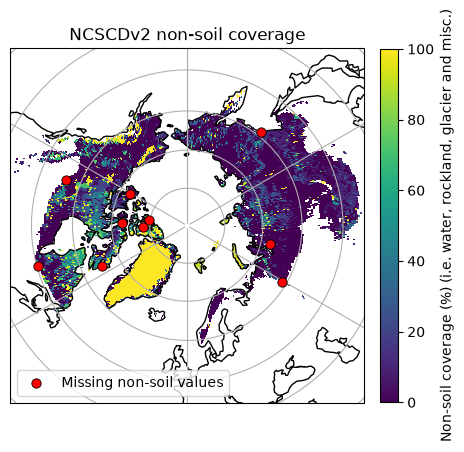

In [277]:
nonsoil = nonsoil_ds["NCSCDv2"]
cmap = plt.cm.viridis.copy()
cmap.set_bad("white")

# Coordinates where SOC exists but non-soil coverage is NaN
missing_lon = [141.75, -92.75, -74.75, -64.75, -110.75, -99.25, -88.75, 59.25, -118.75, 77.75]
missing_lat = [58.75, 72.75, 50.25, 65.25, 56.25, 79.75, 78.25, 61.25, 72.75, 67.75]

fig, ax = plt.subplots(figsize=(5,5), subplot_kw={"projection": ccrs.NorthPolarStereo()})
nonsoil.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, x="lon", y="lat", add_colorbar=True,
             cbar_kwargs={"shrink": 1, "fraction": 0.0456, "pad": 0.04,
                          "label": "Non-soil coverage (%) (i.e. water, rockland, glacier and misc.)"})

ax.scatter(missing_lon, missing_lat, transform=ccrs.PlateCarree(), color="red",
           marker="o", s=45, edgecolor="black", linewidth=0.6, label="Missing non-soil values", zorder=10)

ax.set_extent([-180, 180, 45, 90], crs=ccrs.PlateCarree())
ax.coastlines()
ax.gridlines()
ax.set_title("NCSCDv2 non-soil coverage")
ax.legend(loc="lower left")
plt.show()

Conclusion: the missing non-soil values lie on the edges of land and sea. Ok to remove these rows.

In [278]:
# Look at the nonsoil data variable
nonsoil = nonsoil_ds["NCSCDv2"]
print(nonsoil.to_dataframe().describe())

# count the number of non-NaN values in the dataset
non_nan_count = np.count_nonzero(~np.isnan(nonsoil.values))
print("\nNumber of non-NaN values:", non_nan_count)
print("Total number of values:", nonsoil.size)
print("Percentage of non-NaN values:", (non_nan_count / nonsoil.size) * 100, "%")

# Look at the latitude and longitude values
print("\n", nonsoil_ds.lat.values[:10])
print(nonsoil_ds.lon.values[:10])
print("Lat spacing:", np.diff(nonsoil_ds.lat.values[:10]))
print("Lon spacing:", np.diff(nonsoil_ds.lon.values[:10]))

            NCSCDv2
count  17947.000000
mean      27.268736
std       37.387192
min        0.000000
25%        0.000000
50%        5.000000
75%       41.000000
max      100.000000

Number of non-NaN values: 17947
Total number of values: 79920
Percentage of non-NaN values: 22.456206206206204 %

 [89.75 89.25 88.75 88.25 87.75 87.25 86.75 86.25 85.75 85.25]
[-179.75 -179.25 -178.75 -178.25 -177.75 -177.25 -176.75 -176.25 -175.75
 -175.25]
Lat spacing: [-0.5 -0.5 -0.5 -0.5 -0.5 -0.5 -0.5 -0.5 -0.5]
Lon spacing: [0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5]


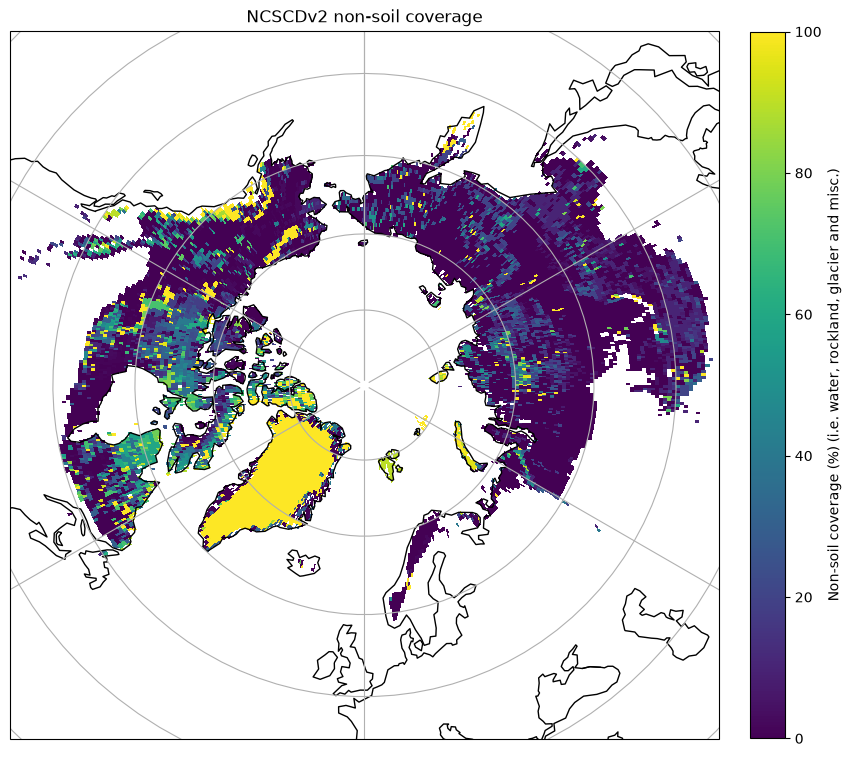

In [279]:
nonsoil = nonsoil_ds["NCSCDv2"]
cmap = plt.cm.viridis.copy()
cmap.set_bad("white")

fig, ax = plt.subplots(figsize=(10,10), subplot_kw={"projection": ccrs.NorthPolarStereo()})
nonsoil.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, x="lon", y="lat", add_colorbar=True,
             cbar_kwargs={"shrink": 1, "fraction": 0.0456, "pad": 0.04,
                          "label": "Non-soil coverage (%) (i.e. water, rockland, glacier and misc.)"})
ax.set_extent([-180, 180, 45, 90], crs=ccrs.PlateCarree())
ax.coastlines()
ax.gridlines()
ax.set_title("NCSCDv2 non-soil coverage")
plt.show()

In [280]:
# Look at the Soil Organic Carbon data
soc = soc_ds["NCSCDv2"]
soc_df = soc.to_dataframe()
print(soc_df.describe())

# count the number of non-NaN values in the dataset
non_nan_count_soc = np.count_nonzero(~np.isnan(soc.values))
print("\nNumber of non-NaN values:", non_nan_count_soc)
print("Total number of values:", soc.size)
print("Percentage of non-NaN values:", (non_nan_count_soc / soc.size)*100, "%")

            NCSCDv2
count  17904.000000
mean     200.756195
std      165.194794
min        0.000000
25%       60.000000
50%      178.000000
75%      320.250000
max     1228.000000

Number of non-NaN values: 17904
Total number of values: 79920
Percentage of non-NaN values: 22.4024024024024 %


/Users/andrearaaschou/courses/BERN02/.venv/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:301: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)


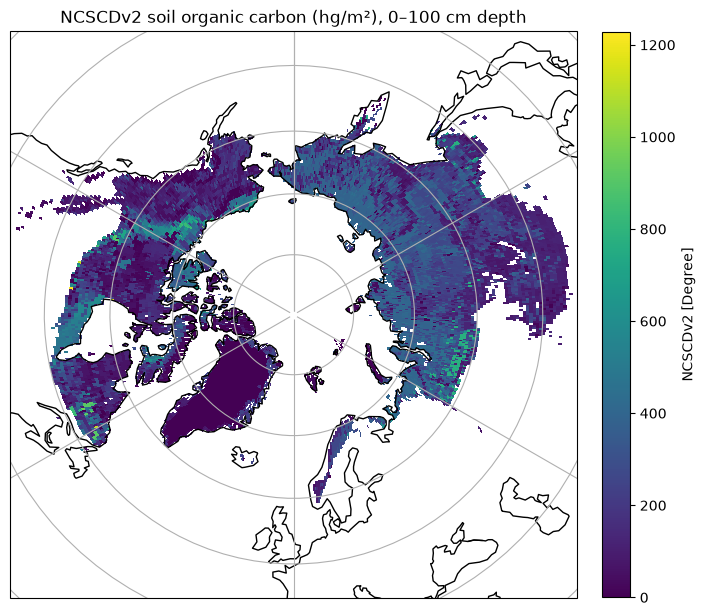

In [281]:
# Plot soil organic carbon content
cmap = plt.cm.viridis.copy()
cmap.set_bad("white")

fig, ax = plt.subplots(figsize=(8,8), subplot_kw={"projection": ccrs.NorthPolarStereo()})
soc.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, x="lon", y="lat", add_colorbar=True,
         cbar_kwargs={"shrink": 1, "fraction": 0.0456, "pad": 0.04})
ax.set_extent([-180, 180, 45, 90], crs=ccrs.PlateCarree())
ax.coastlines()
ax.gridlines()
ax.set_title("NCSCDv2 soil organic carbon (hg/m²), 0–100 cm depth")
plt.show()

In [282]:
print(merged_df[["Lon", "Lat", "SoilC_lpj", "NCSCD_SOCC100"]].head(10))
print("\nTotal LPJ cells:", len(merged_df))
print("NCSCD values:", merged_df["NCSCD_SOCC100"].notna().sum())
print("Percentage with NCSCD:", merged_df["NCSCD_SOCC100"].notna().mean() * 100)

      Lon    Lat  SoilC_lpj  NCSCD_SOCC100
0  166.25  60.25     29.138            NaN
1  -65.25  50.75     27.382            NaN
2   90.75  36.75      0.282            NaN
3  178.75  65.75     17.307          402.0
4  155.75  64.75     25.261          384.0
5   71.75  67.75     26.257          308.0
6   24.25  51.75     16.046            NaN
7 -102.75  63.25     13.338          209.0
8  -97.25  39.25      6.069            NaN
9 -111.75  71.25      0.037          474.0

Total LPJ cells: 26523
NCSCD values: 13138
Percentage with NCSCD: 49.53436639897448


In [283]:
# Check for alignment between the two dataframes (lon and lat values)
matched_lon = soc.sel(lon=lpj_coords.lon, method="nearest").lon.values
matched_lat = soc.sel(lat=lpj_coords.lat, method="nearest").lat.values
lon_diff = np.abs(lpj_df["Lon"].values - matched_lon)
lat_diff = np.abs(lpj_df["Lat"].values - matched_lat)
print("Grid alignment check:")
print("Max longitude difference:", lon_diff.max())
print("Max latitude difference:", lat_diff.max())
print("Mean longitude difference:", lon_diff.mean())
print("Mean latitude difference:", lat_diff.mean())

Grid alignment check:
Max longitude difference: 0.005198384072059525
Max latitude difference: 0.0020860709467598326
Mean longitude difference: 0.005198384072059525
Mean latitude difference: 0.0020860709467598326


### Randomly sample 10 NaN values to check if they are sea or land

In [284]:
sampled_rows = lpj_df[lpj_df["NCSCD_SOCC100"].isna()].sample(n=10, random_state = 2)
print(sampled_rows[["Lon", "Lat", "NCSCD_SOCC100"]])

          Lon    Lat  NCSCD_SOCC100
9655    68.75  50.25            NaN
38307 -124.25  42.75            NaN
34066   29.25  49.25            NaN
5946  -104.75  41.25            NaN
29557  132.25  46.75            NaN
35759   72.75  57.25            NaN
29866 -106.25  47.25            NaN
22419   26.75  63.75            NaN
10260   78.75  49.25            NaN
29237   36.25  41.25            NaN


Coordinates:

 - 37°15'00.0"N 6°15'00.0"W - close to sea but on land
 - 40°45'00.0"N 2°15'00.0"W - on land near Madrid
 - 41°15'00.0"N 89°15'00.0"E - on land in China
 - 39°15'00.0"N 79°45'00.0"E - on land also in China
 - 36°15'00.0"N 51°15'00.0"E - on land in Iran

### Visualize parameters

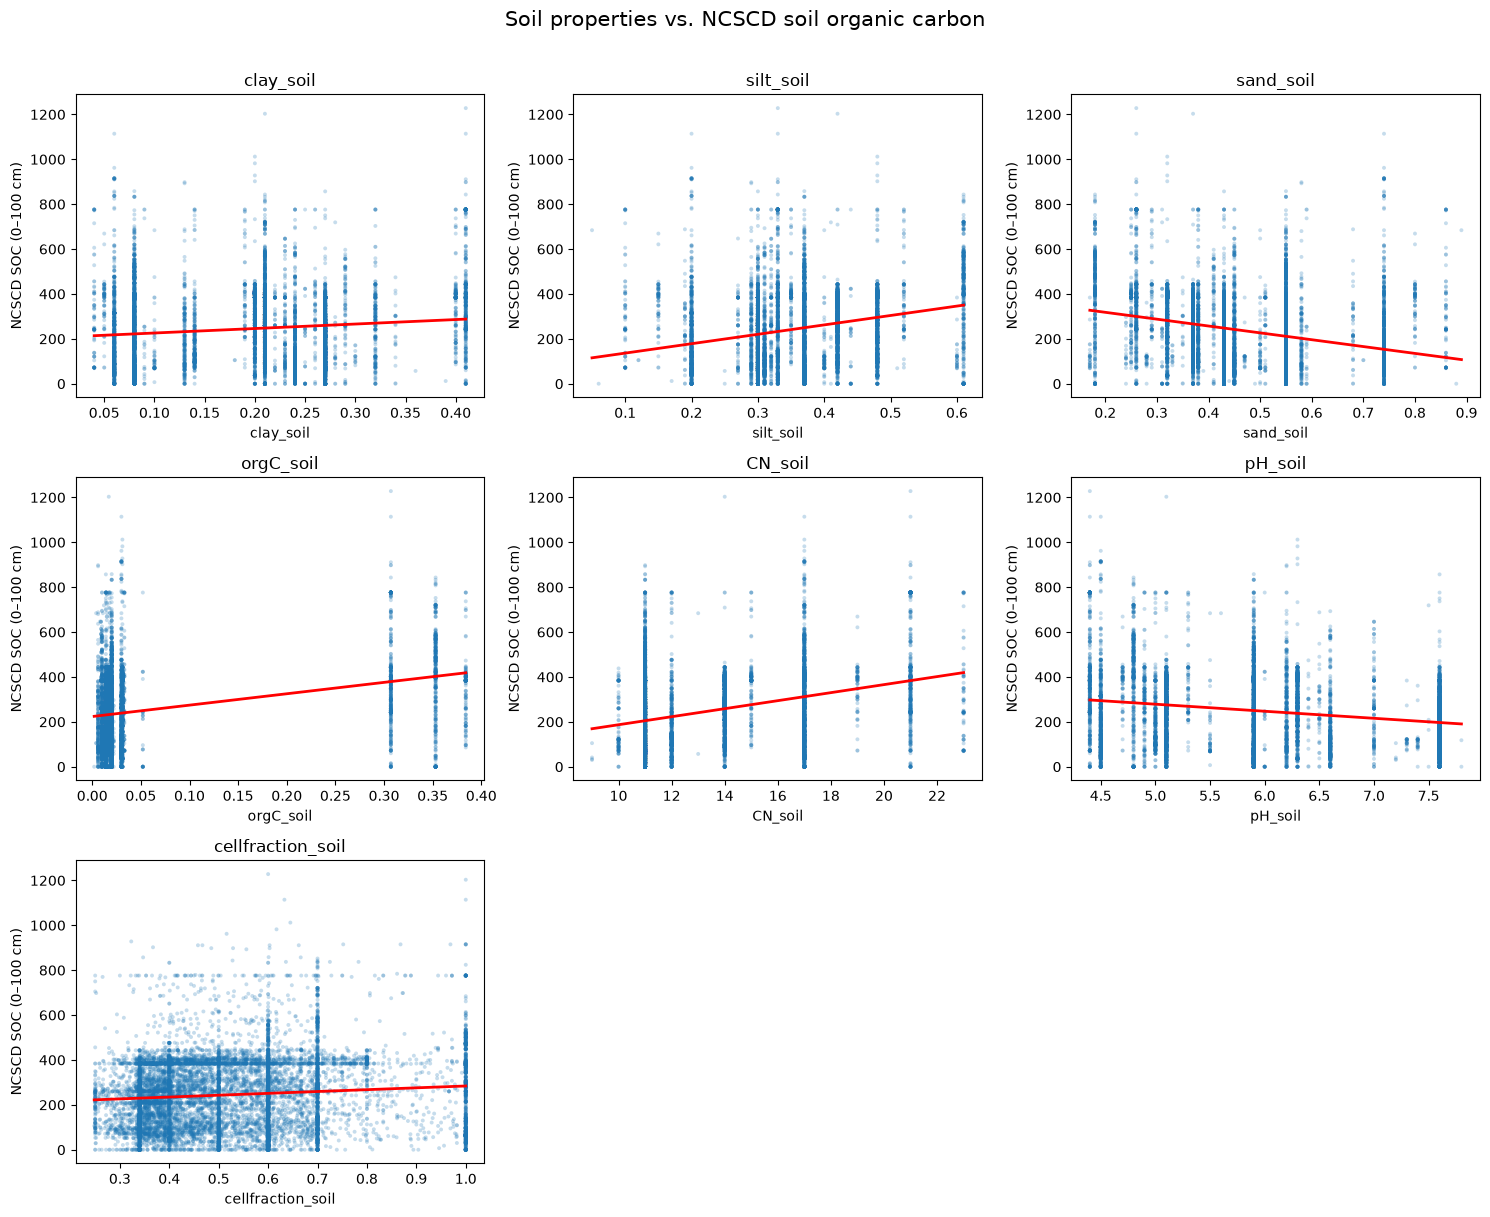

In [285]:
soil_features = [col for col in merged_df.columns if col.endswith("_soil")]
ncols = 3
nrows = math.ceil(len(soil_features) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = np.array(axes).flatten()

for ax, feature in zip(axes, soil_features):
    data = merged_df[[feature, "NCSCD_SOCC100"]].dropna()
    x, y = data[feature], data["NCSCD_SOCC100"]
    ax.scatter(x, y, alpha=0.25, s=8, edgecolors="none")
    if len(data) > 1 and x.nunique() > 1:
        m, b = np.polyfit(x, y, 1)
        x_line = np.linspace(x.min(), x.max(), 100)
        ax.plot(x_line, m * x_line + b, linewidth=2, color = "red")
    ax.set(title=feature, xlabel=feature, ylabel="NCSCD SOC (0–100 cm)")

for ax in axes[len(soil_features):]:
    ax.set_visible(False)

fig.suptitle("Soil properties vs. NCSCD soil organic carbon", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

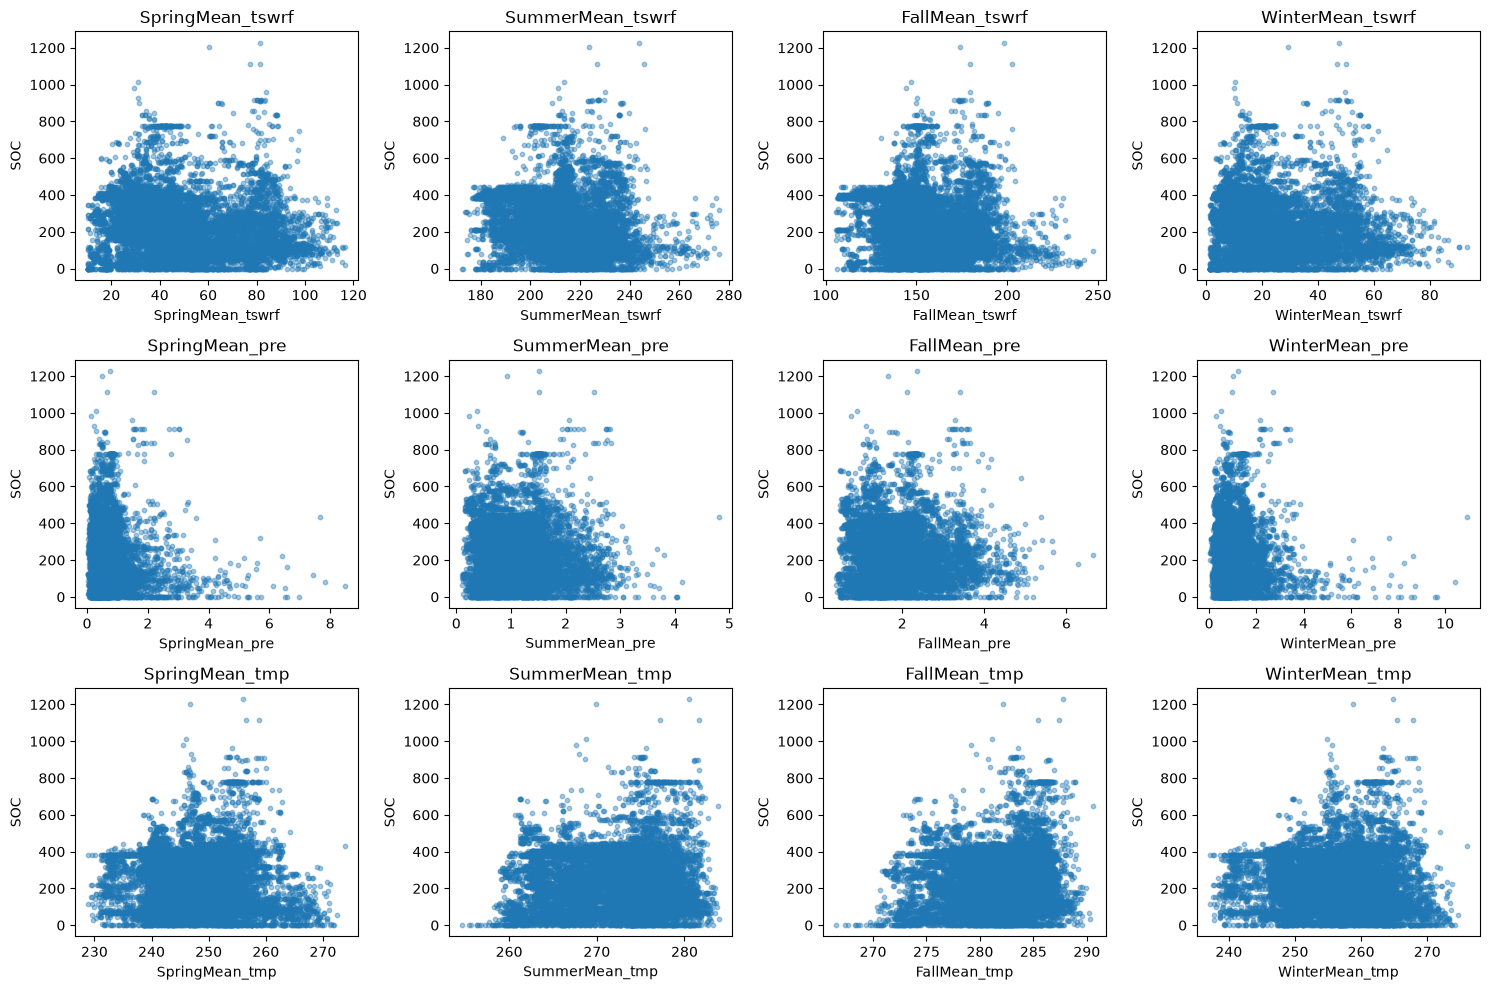

In [286]:
plot_cols = [col for col in merged_df.columns if any(f"Mean_{var}" in col for var in ["tmp", "pre", "tswrf"])]

fig, axes = plt.subplots(3, (len(plot_cols) + 2) // 3, figsize=(15, 10))
for ax, col in zip(axes.flat, plot_cols):
    ax.scatter(merged_df[col], merged_df['NCSCD_SOCC100'], alpha=0.4, s=10)
    ax.set(xlabel=col, ylabel="SOC", title=col)
for ax in axes.flat[len(plot_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

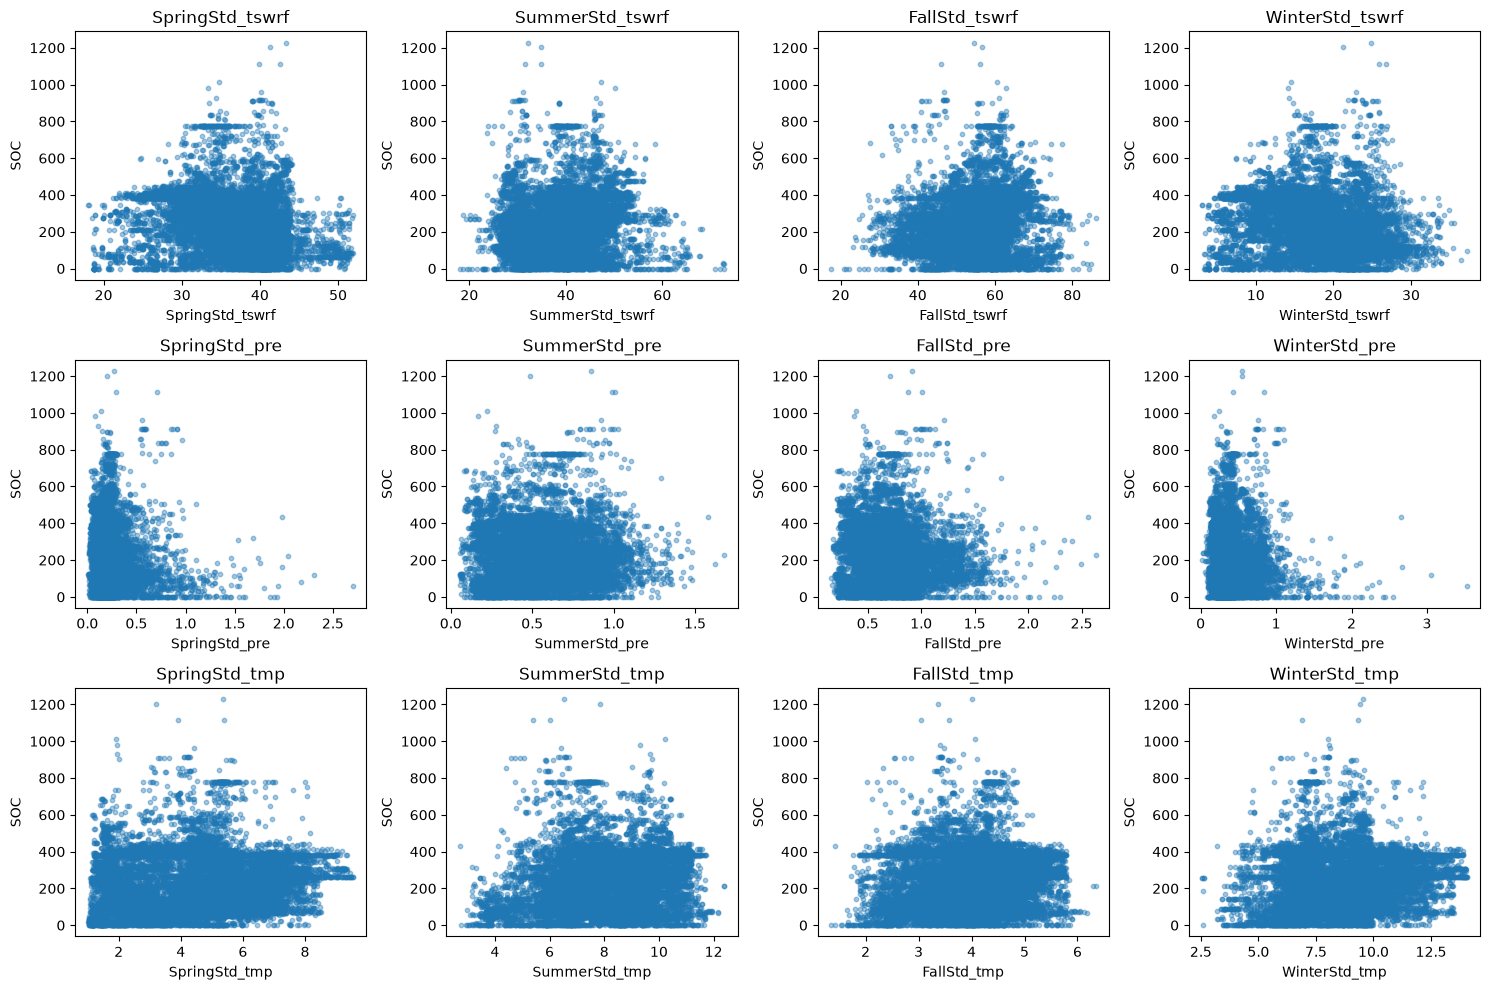

In [287]:
plot_cols = [col for col in merged_df.columns if any(f"Std_{var}" in col for var in ["tmp", "pre", "tswrf"])]

fig, axes = plt.subplots(3, (len(plot_cols) + 2) // 3, figsize=(15, 10))
for ax, col in zip(axes.flat, plot_cols):
    ax.scatter(merged_df[col], merged_df["NCSCD_SOCC100"], alpha=0.4, s=10)
    ax.set(xlabel=col, ylabel="SOC", title=col)
for ax in axes.flat[len(plot_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

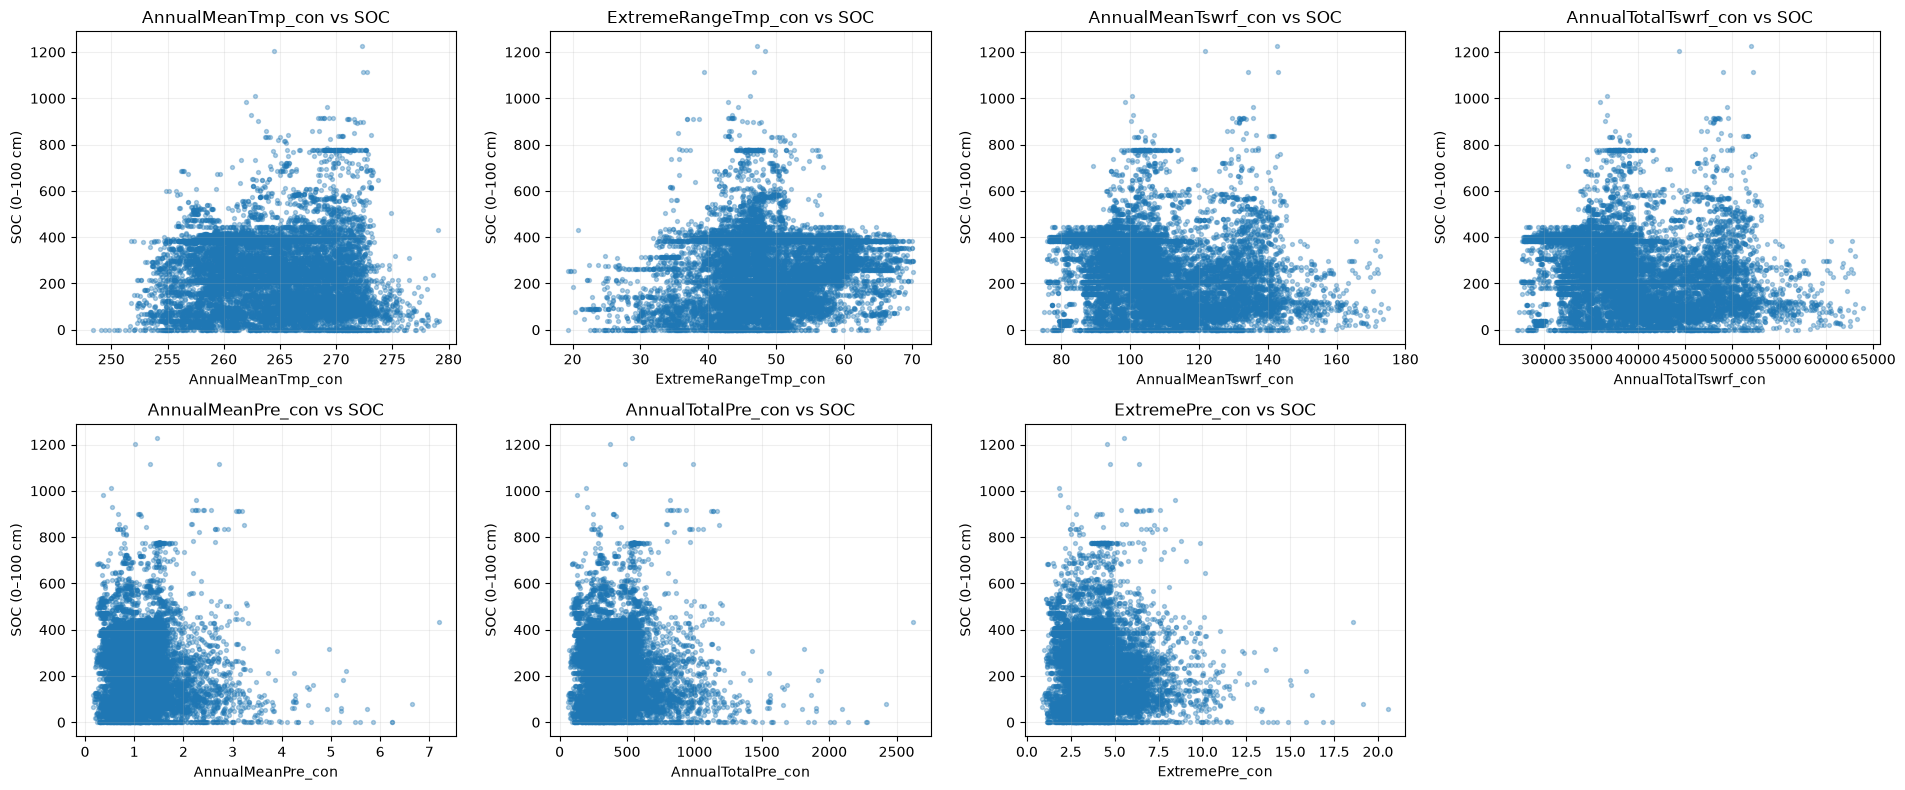

In [288]:
target = "NCSCD_SOCC100"
home_features = [
    "AnnualMeanTmp_con",
    "ExtremeRangeTmp_con",
    "AnnualMeanTswrf_con",
    "AnnualTotalTswrf_con",
    "AnnualMeanPre_con",
    "AnnualTotalPre_con",
    "ExtremePre_con"
]

ncols = 4
nrows = math.ceil(len(home_features) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(19, 4 * nrows))
axes = axes.flatten()

for ax, feature in zip(axes, home_features):
    ax.scatter(merged_df[feature], merged_df[target], alpha=0.35, s=8)
    ax.set(xlabel=feature, ylabel="SOC (0–100 cm)", title=f"{feature} vs SOC")
    ax.grid(alpha=0.2)

for ax in axes[len(home_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

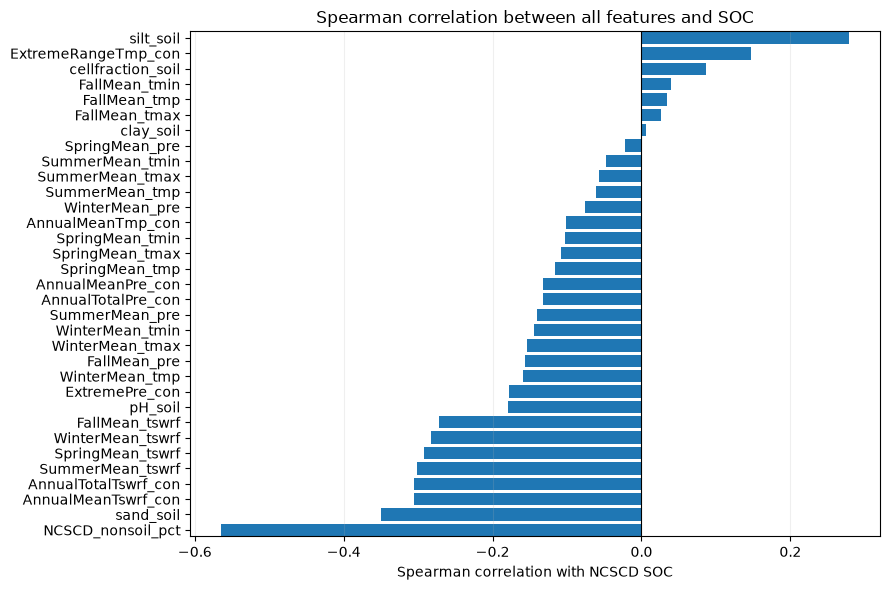

In [289]:
target = "NCSCD_SOCC100"
exclude = ["Lon", "Lat", target]
"""features = [col for col in merged_df.select_dtypes(include="number").columns if col not in exclude and not col.endswith("_grid") and not col.endswith("_lpj")]"""
features = [col for col in merged_df.select_dtypes(include="number").columns if col not in exclude and not col.endswith("_grid") and not col.endswith("_lpj")
            and "Std" not in col and "CN_soil" not in col and "orgC_soil" not in col and "Median" not in col]

results = []
for col in features:
    data = merged_df[[col, target]].dropna()
    if len(data) >= 3 and data[col].nunique() > 1 and data[target].nunique() > 1:
        results.append({"Feature": col, "Pearson": data[col].corr(data[target], method="pearson"), "Spearman": data[col].corr(data[target], method="spearman"), "N": len(data)})

corr_df = pd.DataFrame(results)
corr_df["Abs Pearson"] = corr_df["Pearson"].abs()
corr_df["Abs Spearman"] = corr_df["Spearman"].abs()
corr_df = corr_df.sort_values("Abs Spearman", ascending=False)
#print(corr_df[["Feature", "Pearson", "Spearman", "N"]].to_string(index=False))

top = corr_df.sort_values("Spearman")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["Feature"], top["Spearman"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Spearman correlation with NCSCD SOC", title="Spearman correlation between all features and SOC")
ax.grid(axis="x", alpha=0.2)
ax.margins(y=0.001)
plt.tight_layout()
plt.show()


## Neural Network

### Add weights to each row (using non-soil coverage)

In [292]:
weights = 1 - merged_df["NCSCD_nonsoil_pct"] / 100 # if 20 % if non-soil, the weight is 0,8
merged_df["weights"] = weights

"""data = merged_df.dropna(subset=features + [target, "NCSCD_nonsoil_pct"]).copy()
data["sample_weight"] = 1 - data["NCSCD_nonsoil_pct"] / 100
print("Zero weights:", (data["sample_weight"] == 0).sum())
print("Invalid weights:", ((data["sample_weight"] < 0) | (data["sample_weight"] > 1)).sum())"""

'data = merged_df.dropna(subset=features + [target, "NCSCD_nonsoil_pct"]).copy()\ndata["sample_weight"] = 1 - data["NCSCD_nonsoil_pct"] / 100\nprint("Zero weights:", (data["sample_weight"] == 0).sum())\nprint("Invalid weights:", ((data["sample_weight"] < 0) | (data["sample_weight"] > 1)).sum())'

### Choose geographical section to use as test set

/Users/andrearaaschou/courses/BERN02/.venv/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:301: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)


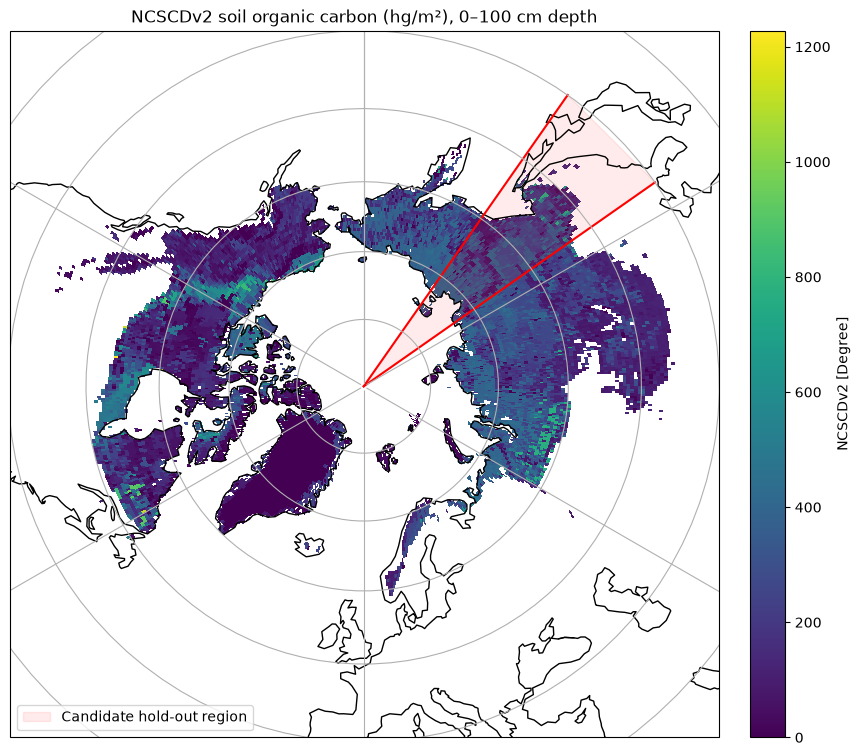

Total observations: 13,117
Test observations: 1,562 (11.91%)
Remaining observations: 11,555 (88.09%)


In [354]:
# Drop rows with nan values
merged_df = merged_df.dropna().reset_index(drop=True)

# Define test mask using coordinates from the cleaned DataFrame
center_lon = 135
sector_width = 20
min_lat = 40

lon = merged_df["Lon"]; lat = merged_df["Lat"]
lon_diff = ((lon - center_lon + 180) % 360) - 180
test_mask = (np.abs(lon_diff) <= sector_width / 2) & (lat >= min_lat)

# Make plot
lon_start = center_lon - sector_width / 2
lon_end = center_lon + sector_width / 2

cmap = plt.cm.viridis.copy()
cmap.set_bad("white")

fig, ax = plt.subplots(figsize=(10,10), subplot_kw={"projection": ccrs.NorthPolarStereo()})
soc.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, x="lon", y="lat", add_colorbar=True,
         cbar_kwargs={"shrink": 1, "fraction": 0.0456, "pad": 0.04})

ax.fill([lon_start, lon_start, lon_end, lon_end], # Overlay the pizza slice
        [min_lat, 90, 90, min_lat],
        transform=ccrs.PlateCarree(), color="red", alpha=0.08,
        label="Candidate hold-out region")

for lon_edge in [lon_start, lon_end]:  # Highlight the slice boundaries
    ax.plot([lon_edge, lon_edge], [min_lat, 90], transform=ccrs.PlateCarree(), color="red", linewidth=1.5)

ax.set_extent([-180, 180, 40, 90], crs=ccrs.PlateCarree())
ax.coastlines()
ax.gridlines()
ax.set_title("NCSCDv2 soil organic carbon (hg/m²), 0–100 cm depth")
ax.legend(loc="lower left")
plt.show()

# Calculate proportion of test set observations againt total number of observations
lon = merged_df["Lon"].to_numpy()
lat = merged_df["Lat"].to_numpy()
lon_diff = (lon - center_lon + 180) % 360 - 180 # Handle longitude wraparound at ±180°
n_total = len(merged_df)
n_test = test_mask.sum()
n_train = n_total - n_test
print(f"Total observations: {n_total:,}")
print(f"Test observations: {n_test:,} ({n_test / n_total:.2%})")
print(f"Remaining observations: {n_train:,} ({n_train / n_total:.2%})")

### Divide data into sets

In [355]:
features = ["AnnualMeanTmp_con", "AnnualTotalPre_con", "ExtremeRangeTmp_con", "ExtremePre_con", "AnnualTotalTswrf_con", "sand_soil", "silt_soil"] # "clay_soil" - clear improvement when removing clay soil. pH improves predictions slightly but not a lot  
target = "NCSCD_SOCC100"

X = merged_df[features].copy()
y = merged_df[target].copy()
weights = merged_df["weights"].copy()

# apply weights
X_region_train = X.loc[~test_mask]
y_region_train = y.loc[~test_mask]
w_region_train = weights.loc[~test_mask]

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]
w_test = weights.loc[test_mask]

# Split the remaining region into training and validation sets
X_train, X_val, y_train, y_val, w_train, w_val = train_test_split(
    X_region_train, y_region_train, w_region_train,
    test_size=0.2, random_state=42
)

# Fit scaler on training subset only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("X train shape:", X_train.shape)
print("X val shape:", X_val.shape)
print("X test shape:", X_test.shape)
print("y shape:", y.shape)
print("Predictors:", X.columns.tolist())


X train shape: (9244, 7)
X val shape: (2311, 7)
X test shape: (1562, 7)
y shape: (13117,)
Predictors: ['AnnualMeanTmp_con', 'AnnualTotalPre_con', 'ExtremeRangeTmp_con', 'ExtremePre_con', 'AnnualTotalTswrf_con', 'sand_soil', 'silt_soil']


### Build Neural Network

In [356]:
def build_nn(input_dim, hidden_layers=(16, 32, 32, 16), dropout = False, dropout_rate = 0.1, name="soc_model"):
    m = keras.Sequential(name=name)
    m.add(layers.Input(shape=(input_dim,))) # input layer

    for units in hidden_layers: # hidden layers
            m.add(layers.Dense(units, activation="relu"))
            if dropout:
                m.add(layers.Dropout(dropout_rate))

    m.add(layers.Dense(1, activation="relu")) # output layer
    m.compile(loss="mse", optimizer=keras.optimizers.Adam(), metrics=["mae"])
    return m

keras.utils.set_random_seed(0)
nn_model = build_nn(input_dim=len(features))
nn_model.summary()

Model: "soc_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_385 (Dense)               │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_386 (Dense)               │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_387 (Dense)               │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_388 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_389 (Dense)               │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,273 (8.88 KB)

 Trainable params: 2,273 (8.88 KB)

 Non-trainable params: 0 (0.00 B)

### Train and evaluate the NN

In [357]:
def train_model(hidden_layer = (64, 64, 32), dropout_rate = 0.2, weights = False):
    histories, models, results = {}, {}, {}

    for label, use_dropout in [("no dropout", False), ("dropout", True)]:
        keras.utils.set_random_seed(0)
        model = build_nn(
            input_dim=X_train.shape[1], 
            dropout=use_dropout,  
            dropout_rate=dropout_rate, 
            hidden_layers=hidden_layer, 
            name=label.replace(" ", "_"))
        
        early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
        fit_kwargs = {"batch_size": 50, 
                              "epochs": 300, 
                              "validation_data": (X_val, y_val), 
                              "callbacks": [early_stop], 
                              "verbose": 0}
        if weights: # Add training weights to fit_kwargs
            fit_kwargs["sample_weight"] = w_train 
            
        history = model.fit(X_train, y_train, **fit_kwargs) # Fit model
        y_val_pred = model.predict(X_val, verbose=0).ravel() # Evaluate on the validation set
        results[label] = {
            "MAE": mean_absolute_error(y_val, y_val_pred),
            "MSE": mean_squared_error(y_val, y_val_pred),
            "R²": r2_score(y_val, y_val_pred)
        }
        histories[label], models[label] = history.history, model
        print(f"{label:11s}: stopped after {len(history.history['loss']):3d} epochs, "
            f"best val_loss {min(history.history['val_loss']):.2f}, "
            f"val MAE {results[label]['MAE']:.2f}, "
            f"val MSE {results[label]['MSE']:.2f}, "
            f"val R² {results[label]['R²']:.3f}")

        model.save(f"soc_nn_{label.replace(' ', '_')}.keras")

    return histories, models, results

histories, models, results = train_model()

no dropout : stopped after 274 epochs, best val_loss 14735.41, val MAE 84.21, val MSE 14735.41, val R² 0.436
dropout    : stopped after 154 epochs, best val_loss 15586.14, val MAE 90.18, val MSE 15586.13, val R² 0.403


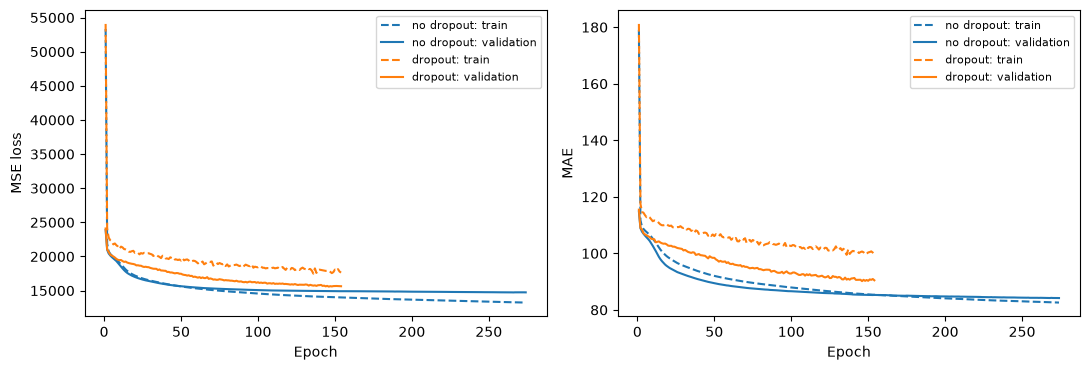

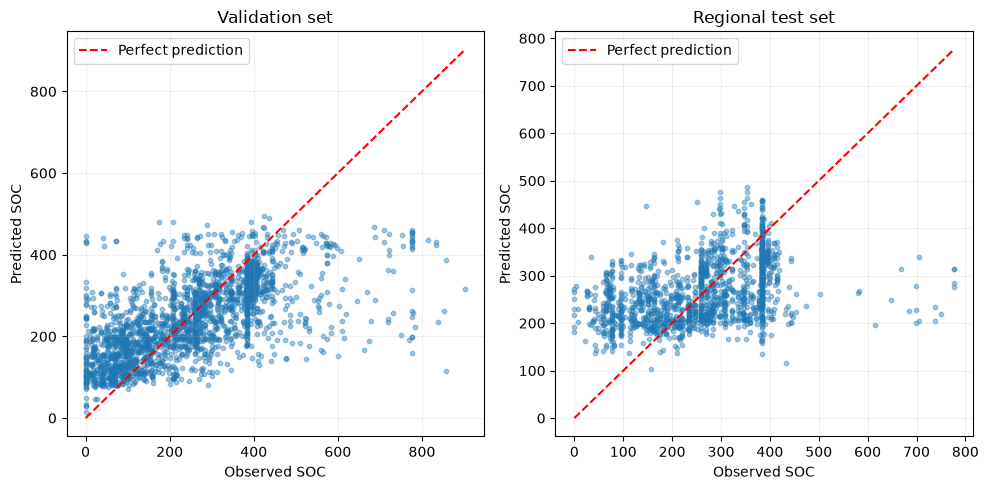

Validation MSE: 14735.4082
Validation MAE: 84.2079
Validation R²:  0.4361

Baseline MSE: 26185.3008
Baseline MAE: 131.4537
Baseline R²:  -0.002153

                  observed   predicted       error
SOC group                                         
(-0.001, 91.0]   46.980000  144.929993   97.949997
(91.0, 199.0]   139.160004  184.050003   44.889999
(199.0, 284.0]  245.000000  253.059998    8.060000
(284.0, 384.0]  347.309998  311.910004  -35.400002
(384.0, 902.0]  481.679993  366.720001 -114.959999

Metric                    Observed   Predicted
Mean                        250.10      251.32
Std deviation               161.64      117.96
Minimum                       0.00        0.00
Maximum                     902.00      601.69


In [358]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for label, c in [("no dropout", "C0"), ("dropout", "C1")]:
    h = histories[label]
    ep = np.arange(1, len(h["loss"]) + 1)
    ax[0].plot(ep, h["loss"], "--", color=c, label=f"{label}: train")
    ax[0].plot(ep, h["val_loss"], "-", color=c, label=f"{label}: validation")
    ax[1].plot(ep, h["mae"], "--", color=c, label=f"{label}: train")
    ax[1].plot(ep, h["val_mae"], "-", color=c, label=f"{label}: validation")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("MSE loss")
ax[0].legend(fontsize=8)
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("MAE")
ax[1].legend(fontsize=8)
plt.tight_layout()

# Predictions for validation and regional test sets
nn_model = models["dropout"]
y_val_pred = nn_model.predict(X_val, verbose=0).ravel()
y_test_pred = nn_model.predict(X_test, verbose=0).ravel()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, y_obs, y_hat, title in [
    (axes[0], y_val, y_val_pred, "Validation set"),
    (axes[1], y_test, y_test_pred, "Regional test set")
]:
    ax.scatter(y_obs, y_hat, alpha=0.4, s=10)
    lims = [min(y_obs.min(), y_hat.min()), max(y_obs.max(), y_hat.max())]
    ax.plot(lims, lims, "r--", label="Perfect prediction")
    ax.set(xlabel="Observed SOC", ylabel="Predicted SOC", title=title)
    ax.grid(alpha=0.2)
    ax.legend()
plt.tight_layout()
plt.show()

# Evaluate on the validation set
nn_model = models["no dropout"]
y_val_pred = nn_model.predict(X_val, verbose=0).ravel()

print(f"Validation MSE: {mean_squared_error(y_val, y_val_pred):.4f}")
print(f"Validation MAE: {mean_absolute_error(y_val, y_val_pred):.4f}")
print(f"Validation R²:  {r2_score(y_val, y_val_pred):.4f}\n")

# Baseline: predict mean SOC from the training set
y_val_baseline = np.full(len(y_val), np.mean(y_train))
print(f"Baseline MSE: {mean_squared_error(y_val, y_val_baseline):.4f}")
print(f"Baseline MAE: {mean_absolute_error(y_val, y_val_baseline):.4f}")
print(f"Baseline R²:  {r2_score(y_val, y_val_baseline):.6f}\n")

diagnostics = pd.DataFrame({"observed": np.asarray(y_val), "predicted": y_val_pred})
diagnostics["error"] = diagnostics["predicted"] - diagnostics["observed"]
diagnostics["SOC group"] = pd.qcut(diagnostics["observed"], q=5, duplicates="drop")
print(diagnostics.groupby("SOC group", observed=True)[["observed", "predicted", "error"]].mean().round(2))

print(f"\n{'Metric':<22}{'Observed':>12}{'Predicted':>12}")
print(f"{'Mean':<22}{np.mean(y_val):>12.2f}{np.mean(y_val_pred):>12.2f}")
print(f"{'Std deviation':<22}{np.std(y_val):>12.2f}{np.std(y_val_pred):>12.2f}")
print(f"{'Minimum':<22}{np.min(y_val):>12.2f}{np.min(y_val_pred):>12.2f}")
print(f"{'Maximum':<22}{np.max(y_val):>12.2f}{np.max(y_val_pred):>12.2f}")

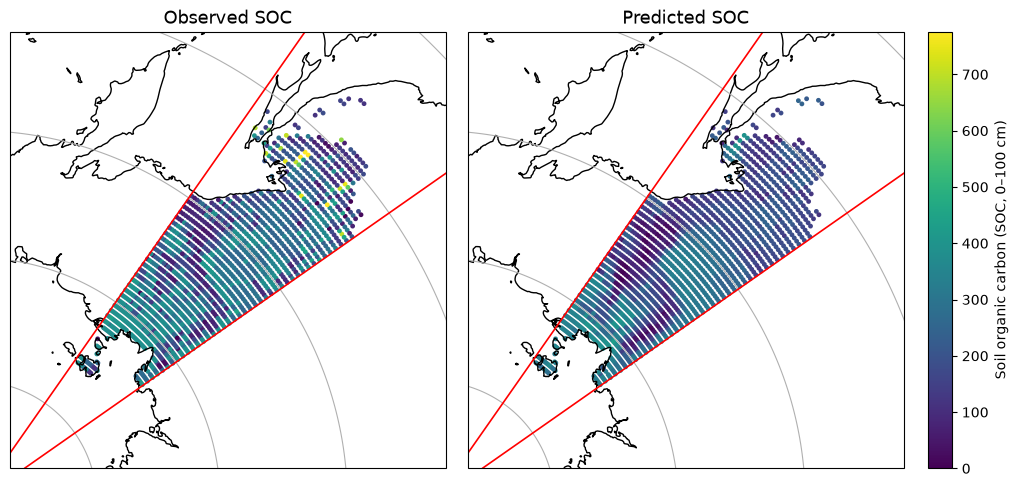

In [398]:
# Get predictions for the geographical test set
y_test_pred = nn_model.predict(X_test, verbose=0).ravel()

# Get test coordinates and observed SOC in the same row order as X_test
test_data = merged_df.loc[test_mask].copy()

assert len(test_data) == len(y_test_pred), "Test coordinates and predictions have different lengths"

target = "NCSCD_SOCC100"
y_test_actual = test_data[target].to_numpy()
lon_test = test_data["Lon"].to_numpy()
lat_test = test_data["Lat"].to_numpy()

# Shared colour scale for fair comparison
vmin = 0
vmax = np.nanmax(y_test_actual)

# Create side-by-side maps
proj = ccrs.NorthPolarStereo()
fig, axes = plt.subplots(1, 2, figsize=(12, 8), subplot_kw={"projection": proj})
plots = [(axes[0], y_test_actual, "Observed SOC"), (axes[1], y_test_pred, "Predicted SOC")]

for ax, values, title in plots:
    sc = ax.scatter(lon_test, lat_test, c=values, transform=ccrs.PlateCarree(),
                    cmap="viridis", vmin=vmin, vmax=vmax, s=12, linewidths=0)
    ax.set_extent([lon_start, lon_end, min_lat+5, 85], crs=ccrs.PlateCarree())
    ax.coastlines()
    gl = ax.gridlines(draw_labels=False)
    gl.xlines = False
    ax.set_title(title, fontsize=13)

    # Highlight the test-region boundaries
    for lon_edge in [lon_start, lon_end]:
        ax.plot([lon_edge, lon_edge], [min_lat+5, 85],
                transform=ccrs.PlateCarree(), color="red", linewidth=1.2)

fig.subplots_adjust(right=0.87, wspace=0.05)
cbar_ax = fig.add_axes([0.89, 0.222, 0.02, 0.546])  # [left, bottom, width, height]
fig.colorbar(sc, cax=cbar_ax, label="Soil organic carbon (SOC, 0–100 cm)")
plt.show()
#plt.tight_layout()


## Unused code

In [ ]:
print("Training SOC quantiles:")
print(y_train.quantile([0, 0.5, 0.9, 0.95, 0.99, 1]).round(2))
print("\nValidation SOC quantiles:")
print(y_val.quantile([0, 0.5, 0.9, 0.95, 0.99, 1]).round(2))

nn_model = models["no dropout"]
y_train_pred = nn_model.predict(X_train, verbose=0).ravel()
for name, y_true, y_hat in [("Train", y_train, y_train_pred), ("Validation", y_val, y_val_pred)]:
    print(f"{name}: MAE={mean_absolute_error(y_true, y_hat):.2f}, MSE={mean_squared_error(y_true, y_hat):.2f}, R²={r2_score(y_true, y_hat):.3f}, observed SD={np.std(y_true):.2f}, predicted SD={np.std(y_hat):.2f}")

Training SOC quantiles:
0.00       0.0
0.50     236.0
0.90     410.0
0.95     491.0
0.99     776.0
1.00    1228.0
Name: NCSCD_SOCC100, dtype: float64

Validation SOC quantiles:
0.00       0.0
0.50     234.0
0.90     414.0
0.95     498.0
0.99     776.0
1.00    1114.0
Name: NCSCD_SOCC100, dtype: float64
Train: MAE=82.05, MSE=12872.44, R²=0.505, observed SD=161.30, predicted SD=111.83
Validation: MAE=88.81, MSE=15795.69, R²=0.405, observed SD=162.92, predicted SD=110.47


In [ ]:
# Drop rows with nan values
merged_df = merged_df.dropna().reset_index(drop=True)

# Drop median columns
merged_df = drop_columns(merged_df, "Median")
merged_df = drop_columns(merged_df, "Std")
merged_df = drop_columns(merged_df, "_lpj")
merged_df = drop_columns(merged_df, "_grid")
merged_df = drop_columns(merged_df, "orgC_soil")
merged_df = drop_columns(merged_df, "CN_soil")
merged_df = drop_columns(merged_df, "cellfraction_soil")

merged_df.shape

Notes: 
 - copy the stuff from the convolutional neural network from the first exercise
 - 3-4 layers
 - per parameter I want 10 datapoints (1/N)^4 then i can have 8-10 input features ish. if then i have 6 points per parameter. better with less imput features. 10 features, 4 layers = 10 000 parameters (weights)
 - dont have enough datapoints to make a transformer
 - Presentation is 10 minutes
